# 3. Analyse der Freitext-Fragen

Workflow:
1. Freitextantworten exportieren
2. Manuell (z. B. in Excel) eine Kategorie je Antwort in der Spalte `category` vergeben
3. Codierte Datei wieder einlesen und Häufigkeiten auswerten
4. Zusätzlich automatische Sentiment-Analyse (VADER, Englisch)

In [36]:
import sys
from pathlib import Path

import pandas as pd

sys.path.append(str(Path.cwd().parent))
from src.utils import (
    export_open_text_for_coding,
    plot_category_frequency,
    analyze_sentiment,
    plot_sentiment_distribution,
    save_figure,
)

PROCESSED_PATH = Path("../data/processed/survey_clean.csv")
df = pd.read_csv(PROCESSED_PATH)
ID_COLUMN = "Response ID"
cols = df.columns

# Die drei offenen Freitext-Fragen der Umfrage (slug -> Spalte)
OPEN_TEXT_QUESTIONS = {
    "process_factors": cols[53],           # Einflussfaktoren auf die Wahl des Entwicklungsprozesses
    "similar_or_different_reason": cols[55],  # Begründung: Space-SE vs. andere Domänen
    "anything_else": cols[56],             # Sonstige Anmerkungen
}
OPEN_TEXT_QUESTIONS

{'process_factors': 'Which factors have the greatest influence on the choice or adaption of the software development process?',
 'similar_or_different_reason': 'In your opinion, will software engineering in the space sector and software engineering in other domains become more similar or more different in the future?\xa0Please briefly explain the reason for your answer. [Comment]',
 'anything_else': 'Is there anything else you would like to share that is relevant to this topic?'}

## Schritt 1: Export zur manuellen Codierung

In [37]:
for slug, column in OPEN_TEXT_QUESTIONS.items():
    export_path = export_open_text_for_coding(
        df, text_column=column, out_path=f"../data/processed/{slug}_zur_codierung.csv", id_column=ID_COLUMN
    )
    print(f"[{slug}] Bitte manuell Kategorien in 'category' eintragen: {export_path.resolve()}")

[process_factors] Bitte manuell Kategorien in 'category' eintragen: C:\Users\andre\OneDrive - Chemische Werke Kluthe GmbH\Dokumente\Vorlesungen 8tes Semester\Bachelorarbeit\Analysis Survey\data\processed\process_factors_zur_codierung.csv
[similar_or_different_reason] Bitte manuell Kategorien in 'category' eintragen: C:\Users\andre\OneDrive - Chemische Werke Kluthe GmbH\Dokumente\Vorlesungen 8tes Semester\Bachelorarbeit\Analysis Survey\data\processed\similar_or_different_reason_zur_codierung.csv
[anything_else] Bitte manuell Kategorien in 'category' eintragen: C:\Users\andre\OneDrive - Chemische Werke Kluthe GmbH\Dokumente\Vorlesungen 8tes Semester\Bachelorarbeit\Analysis Survey\data\processed\anything_else_zur_codierung.csv


## Schritt 2: Codierte Datei einlesen und auswerten

Erst ausführen, nachdem die Kategorien manuell vergeben wurden.

In [38]:
coded_data = {}
for slug in OPEN_TEXT_QUESTIONS:
    coded_path = Path(f"../data/processed/{slug}_zur_codierung.csv")
    coded_data[slug] = pd.read_csv(coded_path)

coded_data["process_factors"]["category"].value_counts()

category
Standards & Regulatorik            6
Zeitplan/Zeitdruck                 3
Team-/persoenliche Faktoren        3
Missions-/Projektanforderungen     2
Tooling/Automatisierung            1
Kooperation/Kunden                 1
Nicht-funktionale Anforderungen    1
Name: count, dtype: int64

[anything_else] übersprungen: keine Antworten für diese Frage vorhanden.


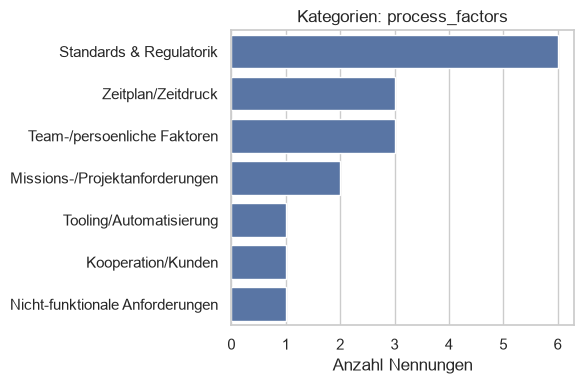

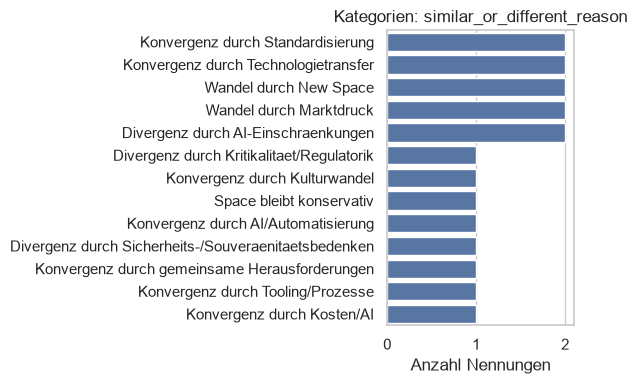

In [39]:
for slug, coded_df in coded_data.items():
    if coded_df.empty:
        print(f"[{slug}] übersprungen: keine Antworten für diese Frage vorhanden.")
        continue
    fig = plot_category_frequency(coded_df, title=f"Kategorien: {slug}")
    save_figure(fig, f"{slug}_kategorien")

## Schritt 3: Sentiment-Analyse (automatisch)

In [40]:
sentiment_data = {}
for slug, column in OPEN_TEXT_QUESTIONS.items():
    sentiment_data[slug] = analyze_sentiment(df, text_column=column)

sentiment_data["process_factors"][[OPEN_TEXT_QUESTIONS["process_factors"], "sentiment_compound", "sentiment_label"]].head()

,Which factors have the greatest influence on the choice or adaption of the software development process?,sentiment_compound,sentiment_label
0,NaN,0.0000,neutral
1,- ECSS standards\n- Previous experience of the...,0.2732,positiv
2,NaN,0.0000,neutral
3,Acceptance by the customers (ESA or NASA stand...,0.4588,positiv
4,NaN,0.0000,neutral


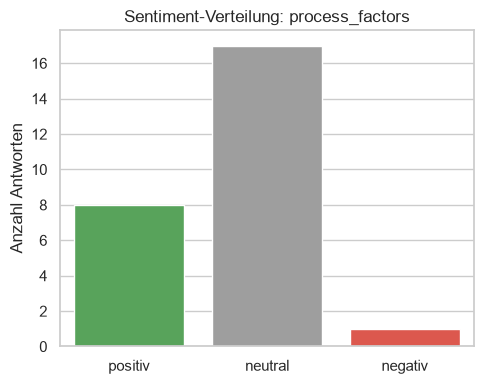

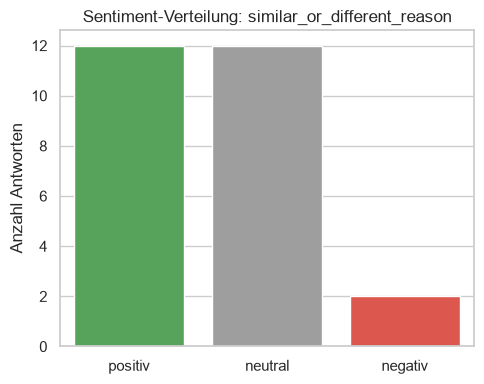

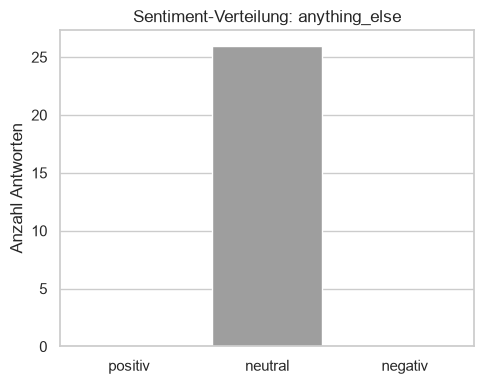

In [41]:
for slug, sentiment_df in sentiment_data.items():
    fig = plot_sentiment_distribution(sentiment_df, title=f"Sentiment-Verteilung: {slug}")
    save_figure(fig, f"{slug}_sentiment")